# Removing Missing Values 

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('netflix_titles.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [6]:
df.sample()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
7722,s7723,Movie,Pee-wee's Playhouse: Christmas Special,"Paul Reubens, Wayne Orr","Paul Reubens, Annette Funicello, Frankie Avalo...",United States,"December 18, 2014",1988,TV-PG,48 min,Movies,"Amid an avalanche of stars, Pee-wee straps on ..."


In [7]:
(7982/8807)*100

90.63245145906666

In [8]:
missing_cols = [x for x in df.columns if df[x].isnull().mean()<0.05 and df[x].isnull().mean()>0]
missing_cols

['date_added', 'rating', 'duration']

In [9]:
df['date_added'].isnull().mean()*100

np.float64(0.11354604292040424)

In [10]:
max(df[missing_cols].isnull().count())

8807

In [11]:
new_df = df[missing_cols].dropna()

In [12]:
df.shape, new_df.shape

((8807, 12), (8790, 3))

In [27]:
# 1. Set the figure size FIRST

plt.figure(figsize=(12, 6))
for col in new_df.columns:
    if df[col].value_counts().count()>10:
        continue
    bg_color = '#f7fff7'   # medium-dark shade related to #c07c82
    grid_color = '#33202a' # light grid for contrast
    
    plt.figure(figsize=(12, 6))
    ax = plt.gca()

# Set background colors
    ax.set_facecolor(bg_color)       # axes background
    plt.gcf().set_facecolor(bg_color)  # figure background (optional)
    # 2. Create the histogram (without figsize)
    plt.hist(new_df[col], density=True, edgecolor = 'white', color='#033c42', label = col, )
    # Add grid
    ax.grid(
        True,
              # major and minor
       
        linewidth=0.7,
        color=grid_color,
        alpha=0.2,
    )
    
    # Optional: minor ticks for nicer grid
    ax.minorticks_on()
    plt.legend()
    plt.tight_layout()
    # 3. Display the plot
    plt.show()

<Figure size 1200x600 with 0 Axes>

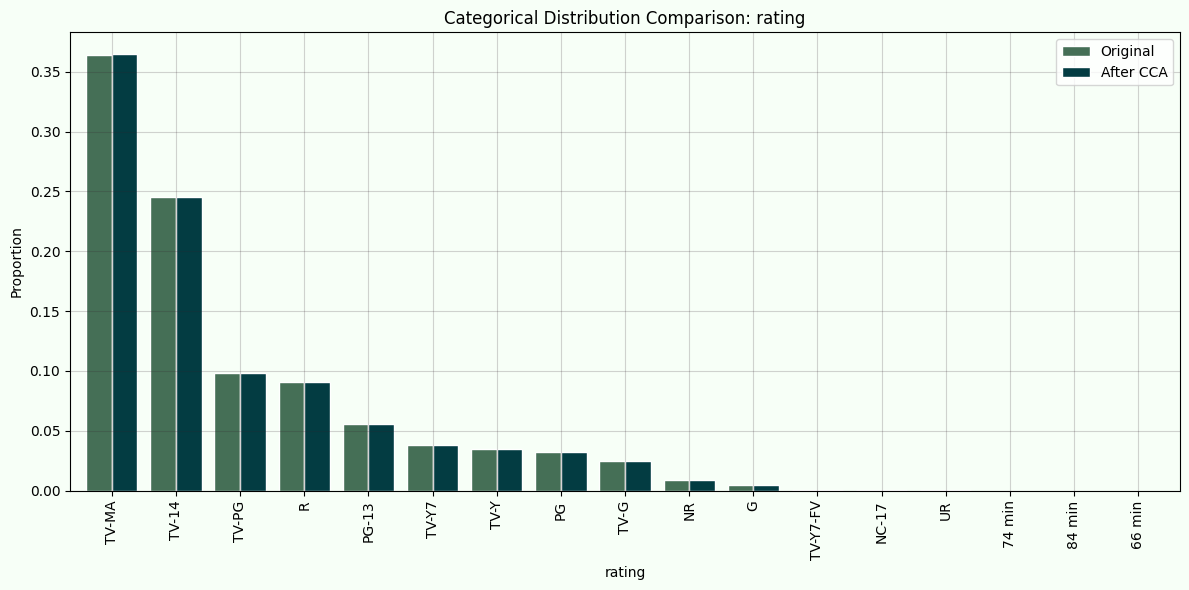

In [22]:

bg_color   = '#f7fff7'
grid_color = '#33202a'

for col in new_df.columns:
    # Only categorical columns
    if pd.api.types.is_numeric_dtype(df[col]) :
        continue
    if df[col].value_counts().count()>19:
        continue
    # 1. Relative frequencies
    df_counts     = df[col].value_counts(normalize=True).rename('Original')
    new_df_counts = new_df[col].value_counts(normalize=True).rename('After CCA')
    
    # 2. Combine for plotting
    df_compare = pd.concat([df_counts, new_df_counts], axis=1).fillna(0)
    
    # 3. Plot grouped bar chart
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.set_facecolor(bg_color)
    fig.set_facecolor(bg_color)
    
    df_compare.plot(
        kind='bar',
        ax=ax,
        color=['#456F56', '#033c42'],
        edgecolor='white',
        width=0.8
    )
    
    ax.set_title(f'Categorical Distribution Comparison: {col}')
    ax.set_ylabel('Proportion')
    ax.set_xlabel(col)
    ax.grid(True,color=grid_color, alpha=0.2)
    ax.legend()
    
    plt.tight_layout()
    plt.show()

In [23]:
col = missing_cols[0]
temp = pd.concat([
            # percentage of observations per category, original data
            df[col].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df[col].value_counts() / len(new_df)
        ],
        axis=1)
print("Column :", col)
# add column names
temp.columns = ['original', 'cca']

temp

Column : date_added


,original,cca
date_added,,
"January 1, 2020",0.012377,0.012400
"November 1, 2019",0.010106,0.010125
"March 1, 2018",0.008516,0.008532
"December 31, 2019",0.008402,0.008419
"October 1, 2018",0.008062,0.008077
...,...,...
"December 4, 2016",0.000114,0.000114
"November 21, 2016",0.000114,0.000114
"November 19, 2016",0.000114,0.000114


In [24]:
col = missing_cols[1]
temp = pd.concat([
            # percentage of observations per category, original data
            df[col].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df[col].value_counts() / len(new_df)
        ],
        axis=1)
print("Column :", col)
# add column names
temp.columns = ['original', 'cca']

temp

Column : rating


,original,cca
rating,,
TV-MA,0.364142,0.364619
TV-14,0.245259,0.245392
TV-PG,0.097990,0.097952
R,0.090723,0.090899
PG-13,0.055638,0.055745
TV-Y7,0.037924,0.037884
TV-Y,0.034859,0.034812
PG,0.032588,0.032651
TV-G,0.024980,0.025028


In [25]:
col = missing_cols[2]
temp = pd.concat([
            # percentage of observations per category, original data
            df[col].value_counts() / len(df),

            # percentage of observations per category, cca data
            new_df[col].value_counts() / len(new_df)
        ],
        axis=1)
print("Column :", col)
# add column names
temp.columns = ['original', 'cca']

temp

Column : duration


,original,cca
duration,,
1 Season,0.203588,0.203754
2 Seasons,0.048257,0.047895
3 Seasons,0.022596,0.022526
90 min,0.017259,0.017292
94 min,0.016578,0.016610
...,...,...
16 min,0.000114,0.000114
186 min,0.000114,0.000114
193 min,0.000114,0.000114
